In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
data_path = Path("../data")
output_path = Path("../outputs")
sql_path = Path("../SQL")

output_path.mkdir(exist_ok=True)
sql_path.mkdir(exist_ok=True)

print("Data folder:", data_path.resolve())
print("Output folder:", output_path.resolve())
print("SQL folder:", sql_path.resolve())

Data folder: /home/aditi/Downloads/job projects/ecommerce-growth-analytics/data
Output folder: /home/aditi/Downloads/job projects/ecommerce-growth-analytics/outputs
SQL folder: /home/aditi/Downloads/job projects/ecommerce-growth-analytics/SQL


In [3]:
csv_files = sorted(data_path.glob("*.csv"))

for file in csv_files:
    print(file.name)

print("\nTotal CSV files:", len(csv_files))

olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv

Total CSV files: 9


In [4]:
customers = pd.read_csv(data_path / "olist_customers_dataset.csv")
orders = pd.read_csv(data_path / "olist_orders_dataset.csv")
order_items = pd.read_csv(data_path / "olist_order_items_dataset.csv")
payments = pd.read_csv(data_path / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(data_path / "olist_order_reviews_dataset.csv")
products = pd.read_csv(data_path / "olist_products_dataset.csv")
sellers = pd.read_csv(data_path / "olist_sellers_dataset.csv")
geolocation = pd.read_csv(data_path / "olist_geolocation_dataset.csv")
category_translation = pd.read_csv(data_path / "product_category_name_translation.csv")

datasets = {
    "customers": customers,
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "products": products,
    "sellers": sellers,
    "geolocation": geolocation,
    "category_translation": category_translation
}

print("All datasets loaded successfully.")

All datasets loaded successfully.


In [5]:
dataset_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Cells": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    }
    for name, df in datasets.items()
])

dataset_summary

,Dataset,Rows,Columns,Missing Cells,Duplicate Rows
0,customers,99441,5,0,0
1,orders,99441,8,4908,0
2,order_items,112650,7,0,0
3,payments,103886,5,0,0
4,reviews,99224,7,145903,0
5,products,32951,9,2448,0
6,sellers,3095,4,0,0
7,geolocation,1000163,5,0,261831
8,category_translation,71,2,0,0


In [6]:
for name, df in datasets.items():
    print("\n", "=" * 60)
    print(name.upper())
    print("=" * 60)
    print(df.info())


CUSTOMERS
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB
None

ORDERS
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approv

In [7]:
missing_summary = []

for name, df in datasets.items():
    for column in df.columns:
        missing_count = df[column].isna().sum()

        if missing_count > 0:
            missing_summary.append({
                "Dataset": name,
                "Column": column,
                "Missing Values": missing_count,
                "Missing Percentage": round(
                    missing_count / len(df) * 100, 2
                )
            })

missing_df = pd.DataFrame(missing_summary)

missing_df.sort_values(
    "Missing Percentage",
    ascending=False
)

,Dataset,Column,Missing Values,Missing Percentage
3,reviews,review_comment_title,87656,88.34
4,reviews,review_comment_message,58247,58.70
2,orders,order_delivered_customer_date,2965,2.98
6,products,product_name_lenght,610,1.85
5,products,product_category_name,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
1,orders,order_delivered_carrier_date,1783,1.79
0,orders,order_approved_at,160,0.16
9,products,product_weight_g,2,0.01


In [8]:
duplicate_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Duplicate Rows": df.duplicated().sum()
    }
    for name, df in datasets.items()
])

duplicate_summary

,Dataset,Duplicate Rows
0,customers,0
1,orders,0
2,order_items,0
3,payments,0
4,reviews,0
5,products,0
6,sellers,0
7,geolocation,261831
8,category_translation,0


In [9]:
status_summary = (
    orders["order_status"]
    .value_counts()
    .reset_index()
)

status_summary.columns = ["Order Status", "Orders"]

status_summary["Percentage"] = (
    status_summary["Orders"] / status_summary["Orders"].sum() * 100
).round(2)

status_summary

,Order Status,Orders,Percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


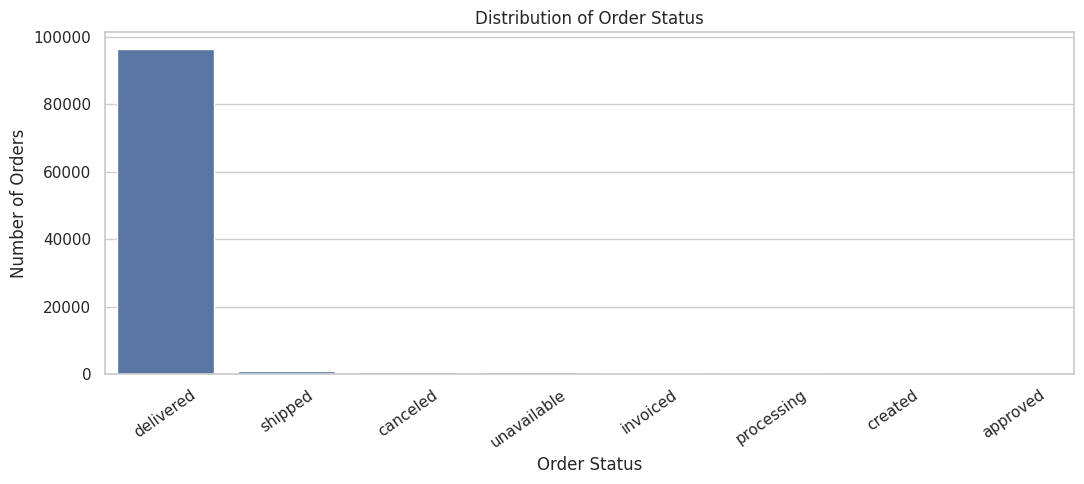

In [10]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=status_summary,
    x="Order Status",
    y="Orders"
)

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(output_path / "order_status_distribution.png", dpi=300)
plt.show()

In [11]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

reviews["review_creation_date"] = pd.to_datetime(
    reviews["review_creation_date"],
    errors="coerce"
)

reviews["review_answer_timestamp"] = pd.to_datetime(
    reviews["review_answer_timestamp"],
    errors="coerce"
)

order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)

print("Date columns converted.")

Date columns converted.


In [12]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Total orders:", len(orders))
print("Delivered orders:", len(delivered_orders))
print(
    "Delivered order percentage:",
    round(len(delivered_orders) / len(orders) * 100, 2),
    "%"
)

Total orders: 99441
Delivered orders: 96478
Delivered order percentage: 97.02 %


In [13]:
customer_orders = delivered_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

customer_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6


In [14]:
order_revenue = order_items.groupby("order_id").agg(
    product_revenue=("price", "sum"),
    freight_revenue=("freight_value", "sum"),
    total_items=("order_item_id", "count")
).reset_index()

order_revenue["total_revenue"] = (
    order_revenue["product_revenue"] +
    order_revenue["freight_revenue"]
)

order_revenue.head()

,order_id,product_revenue,freight_revenue,total_items,total_revenue
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,72.19
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,259.83
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,216.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,218.04


In [15]:
analysis_data = customer_orders.merge(
    order_revenue,
    on="order_id",
    how="left"
)

analysis_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,product_revenue,freight_revenue,total_items,total_revenue
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,29.99,8.72,1,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,118.70,22.76,1,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,159.90,19.22,1,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,45.00,27.20,1,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,19.90,8.72,1,28.62


In [16]:
total_orders = analysis_data["order_id"].nunique()

total_customers = analysis_data["customer_unique_id"].nunique()

total_product_sales = analysis_data["product_revenue"].sum()

total_freight = analysis_data["freight_revenue"].sum()

total_gmv = analysis_data["total_revenue"].sum()

average_order_value = total_gmv / total_orders

kpi_summary = pd.DataFrame({
    "Metric": [
        "Delivered Orders",
        "Unique Customers",
        "Product Sales",
        "Freight Charges",
        "Total GMV (Product + Freight)",
        "Average Order Value"
    ],
    "Value": [
        total_orders,
        total_customers,
        round(total_product_sales, 2),
        round(total_freight, 2),
        round(total_gmv, 2),
        round(average_order_value, 2)
    ]
})

kpi_summary

,Metric,Value
0,Delivered Orders,"96,478.00"
1,Unique Customers,"93,358.00"
2,Product Sales,"13,221,498.11"
3,Freight Charges,"2,198,275.64"
4,Total GMV (Product + Freight),"15,419,773.75"
5,Average Order Value,159.83


In [17]:
customer_frequency = (
    analysis_data.groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

customer_frequency["customer_type"] = np.where(
    customer_frequency["total_orders"] > 1,
    "Repeat Customer",
    "One-time Customer"
)

customer_summary = (
    customer_frequency["customer_type"]
    .value_counts()
    .reset_index()
)

customer_summary.columns = ["Customer Type", "Customers"]

customer_summary["Percentage"] = (
    customer_summary["Customers"] /
    customer_summary["Customers"].sum() * 100
).round(2)

customer_summary

,Customer Type,Customers,Percentage
0,One-time Customer,90557,97.00
1,Repeat Customer,2801,3.00


In [18]:
repeat_customers = customer_frequency[
    customer_frequency["total_orders"] > 1
]["customer_unique_id"].nunique()

one_time_customers = customer_frequency[
    customer_frequency["total_orders"] == 1
]["customer_unique_id"].nunique()

repeat_purchase_rate = (
    repeat_customers / len(customer_frequency) * 100
)

print("Total unique customers:", len(customer_frequency))
print("Repeat customers:", repeat_customers)
print("One-time customers:", one_time_customers)
print("Repeat purchase rate:", round(repeat_purchase_rate, 2), "%")

Total unique customers: 93358
Repeat customers: 2801
One-time customers: 90557
Repeat purchase rate: 3.0 %


In [19]:
customer_value = analysis_data.groupby(
    "customer_unique_id"
).agg(
    total_orders=("order_id", "nunique"),
    total_spend=("total_revenue", "sum"),
    average_order_value=("total_revenue", "mean")
).reset_index()

customer_value["customer_segment"] = np.where(
    customer_value["total_orders"] > 1,
    "Repeat Customer",
    "One-time Customer"
)

segment_analysis = customer_value.groupby(
    "customer_segment"
).agg(
    customers=("customer_unique_id", "count"),
    average_spend=("total_spend", "mean"),
    total_revenue=("total_spend", "sum")
).reset_index()

segment_analysis

,customer_segment,customers,average_spend,total_revenue
0,One-time Customer,90557,160.73,"14,555,586.29"
1,Repeat Customer,2801,308.53,"864,187.46"


In [20]:
segment_analysis["revenue_percentage"] = (
    segment_analysis["total_revenue"] /
    segment_analysis["total_revenue"].sum() * 100
).round(2)

segment_analysis

,customer_segment,customers,average_spend,total_revenue,revenue_percentage
0,One-time Customer,90557,160.73,"14,555,586.29",94.40
1,Repeat Customer,2801,308.53,"864,187.46",5.60


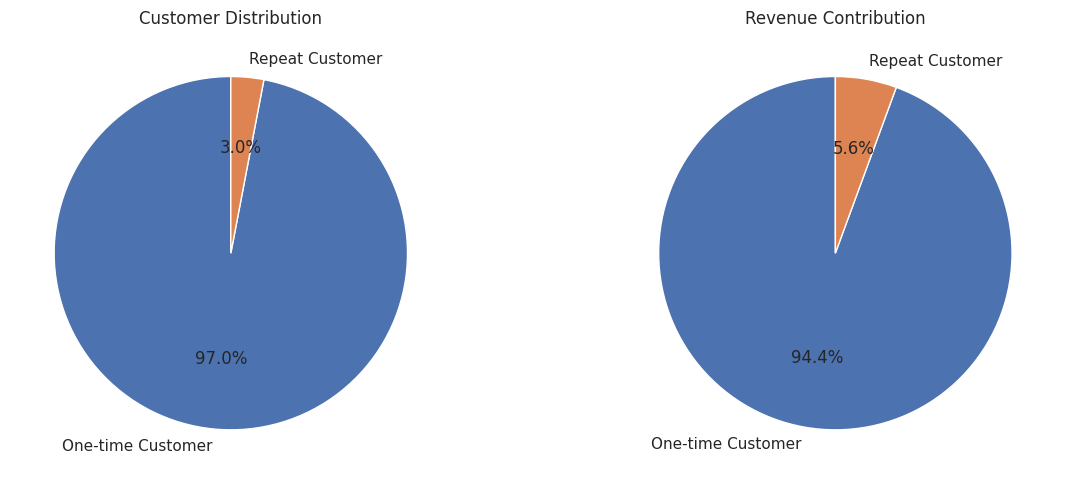

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].pie(
    segment_analysis["customers"],
    labels=segment_analysis["customer_segment"],
    autopct="%1.1f%%",
    startangle=90
)

axes[0].set_title("Customer Distribution")

axes[1].pie(
    segment_analysis["total_revenue"],
    labels=segment_analysis["customer_segment"],
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("Revenue Contribution")

plt.tight_layout()
plt.savefig(output_path / "customer_segment_analysis.png", dpi=300)
plt.show()

In [23]:
analysis_data["month"] = (
    analysis_data["order_purchase_timestamp"]
    .dt.to_period("M").astype(str)
)

first_purchase = (
    analysis_data.groupby("customer_unique_id")["month"]
    .min()
    .reset_index()
)

first_purchase.columns = [
    "customer_unique_id",
    "first_month"
]

monthly_customers = analysis_data.merge(
    first_purchase,
    on="customer_unique_id",
    how="left"
)

monthly_customers["is_new"] = (
    monthly_customers["month"] == monthly_customers["first_month"]
)

monthly_customers["is_repeat"] = (
    monthly_customers["month"] > monthly_customers["first_month"]
)

active = monthly_customers.groupby("month")[
    "customer_unique_id"
].nunique().rename("active_customers")

new = monthly_customers[
    monthly_customers["is_new"]
].groupby("month")[
    "customer_unique_id"
].nunique().rename("new_customers")

repeat = monthly_customers[
    monthly_customers["is_repeat"]
].groupby("month")[
    "customer_unique_id"
].nunique().rename("repeat_customers")

retention_analysis = pd.concat(
    [active, new, repeat],
    axis=1
).fillna(0).reset_index()

retention_analysis[
    ["active_customers", "new_customers", "repeat_customers"]
] = retention_analysis[
    ["active_customers", "new_customers", "repeat_customers"]
].astype(int)

retention_analysis.head(20)

,month,active_customers,new_customers,repeat_customers
0,2016-09,1,1,0
1,2016-10,262,262,0
2,2016-12,1,1,0
3,2017-01,718,717,1
4,2017-02,1630,1628,2
5,2017-03,2508,2503,5
6,2017-04,2274,2256,18
7,2017-05,3479,3451,28
8,2017-06,3076,3037,39
9,2017-07,3802,3752,50


In [24]:
retention_analysis["new_customer_pct"] = (
    retention_analysis["new_customers"] /
    retention_analysis["active_customers"] * 100
)

retention_analysis["repeat_customer_pct"] = (
    retention_analysis["repeat_customers"] /
    retention_analysis["active_customers"] * 100
)

retention_analysis

,month,active_customers,new_customers,repeat_customers,new_customer_pct,repeat_customer_pct
0,2016-09,1,1,0,100.00,0.00
1,2016-10,262,262,0,100.00,0.00
2,2016-12,1,1,0,100.00,0.00
3,2017-01,718,717,1,99.86,0.14
4,2017-02,1630,1628,2,99.88,0.12
5,2017-03,2508,2503,5,99.80,0.20
6,2017-04,2274,2256,18,99.21,0.79
7,2017-05,3479,3451,28,99.20,0.80
8,2017-06,3076,3037,39,98.73,1.27
9,2017-07,3802,3752,50,98.68,1.32


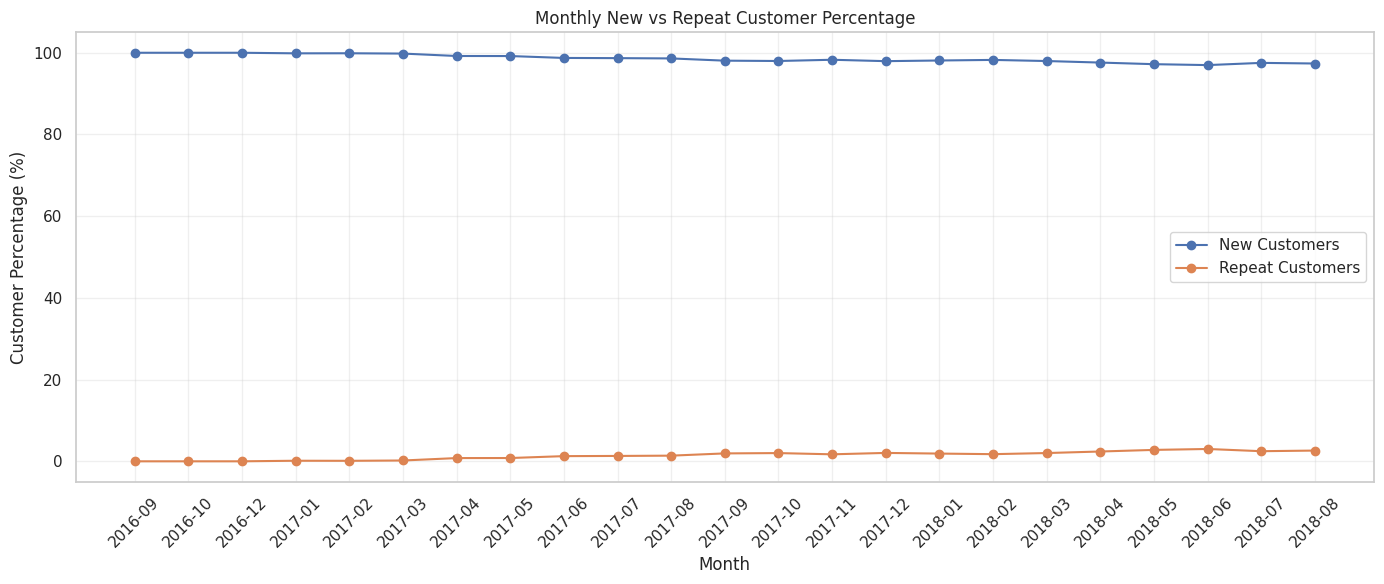

In [25]:
plt.figure(figsize=(14, 6))

plt.plot(
    retention_analysis["month"],
    retention_analysis["new_customer_pct"],
    marker="o",
    label="New Customers"
)

plt.plot(
    retention_analysis["month"],
    retention_analysis["repeat_customer_pct"],
    marker="o",
    label="Repeat Customers"
)

plt.title("Monthly New vs Repeat Customer Percentage")
plt.xlabel("Month")
plt.ylabel("Customer Percentage (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(output_path / "monthly_customer_mix.png", dpi=300)
plt.show()

In [26]:
cohort_data = (
    analysis_data[
        ["customer_unique_id", "order_id", "month"]
    ]
    .drop_duplicates(subset=["customer_unique_id", "month"])
    .copy()
)

cohort_data["order_month"] = pd.PeriodIndex(
    cohort_data["month"], freq="M"
)

cohort_data["cohort_month"] = cohort_data.groupby(
    "customer_unique_id"
)["order_month"].transform("min")

cohort_data["month_number"] = (
    (cohort_data["order_month"].dt.year -
     cohort_data["cohort_month"].dt.year) * 12
    +
    (cohort_data["order_month"].dt.month -
     cohort_data["cohort_month"].dt.month)
)

cohort_data.head(10)

,customer_unique_id,order_id,month,order_month,cohort_month,month_number
0,7c396fd4830fd04220f754e42b4e5bff,e481f51cbdc54678b7cc49136f2d6af7,2017-10,2017-10,2017-09,1
1,af07308b275d755c9edb36a90c618231,53cdb2fc8bc7dce0b6741e2150273451,2018-07,2018-07,2018-07,0
2,3a653a41f6f9fc3d2a113cf8398680e8,47770eb9100c2d0c44946d9cf07ec65d,2018-08,2018-08,2018-08,0
3,7c142cf63193a1473d2e66489a9ae977,949d5b44dbf5de918fe9c16f97b45f8a,2017-11,2017-11,2017-11,0
4,72632f0f9dd73dfee390c9b22eb56dd6,ad21c59c0840e6cb83a9ceb5573f8159,2018-02,2018-02,2018-02,0
5,80bb27c7c16e8f973207a5086ab329e2,a4591c265e18cb1dcee52889e2d8acc3,2017-07,2017-07,2017-07,0
6,932afa1e708222e5821dac9cd5db4cae,6514b8ad8028c9f2cc2374ded245783f,2017-05,2017-05,2017-05,0
7,39382392765b6dc74812866ee5ee92a7,76c6e866289321a7c93b82b54852dc33,2017-01,2017-01,2017-01,0
8,299905e3934e9e181bfb2e164dd4b4f8,e69bfb5eb88e0ed6a785585b27e16dbf,2017-07,2017-07,2017-07,0
9,f2a85dec752b8517b5e58a06ff3cd937,e6ce16cb79ec1d90b1da9085a6118aeb,2017-05,2017-05,2017-05,0


In [27]:
cohort_counts = cohort_data.pivot_table(
    index="cohort_month",
    columns="month_number",
    values="customer_unique_id",
    aggfunc="nunique"
)

cohort_counts

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,262.00,NaN,NaN,NaN,NaN,NaN,1.00,NaN,NaN,1.00,NaN,1.00,NaN,1.00,NaN,1.00,NaN,1.00,2.00,2.00
2016-12,1.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,717.00,2.00,2.00,1.00,3.00,1.00,3.00,1.00,1.00,NaN,3.00,1.00,5.00,3.00,1.00,1.00,2.00,3.00,1.00,NaN
2017-02,"1,628.00",3.00,5.00,2.00,7.00,2.00,4.00,3.00,2.00,3.00,2.00,5.00,2.00,3.00,2.00,1.00,1.00,3.00,NaN,NaN
2017-03,"2,503.00",11.00,9.00,10.00,9.00,4.00,4.00,8.00,8.00,2.00,9.00,3.00,5.00,3.00,4.00,6.00,2.00,3.00,NaN,NaN
2017-04,"2,256.00",14.00,5.00,4.00,6.00,6.00,8.00,7.00,7.00,4.00,6.00,2.00,1.00,1.00,2.00,2.00,3.00,NaN,NaN,NaN
2017-05,"3,451.00",16.00,16.00,10.00,10.00,11.00,14.00,5.00,9.00,9.00,9.00,12.00,8.00,1.00,6.00,7.00,NaN,NaN,NaN,NaN
2017-06,"3,037.00",15.00,12.00,13.00,9.00,12.00,11.00,7.00,4.00,6.00,9.00,11.00,5.00,5.00,7.00,NaN,NaN,NaN,NaN,NaN


In [28]:
cohort_sizes = cohort_counts[0]

cohort_retention = cohort_counts.divide(
    cohort_sizes,
    axis=0
) * 100

cohort_retention = cohort_retention.round(2)

cohort_retention

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.00,NaN,NaN,NaN,NaN,NaN,0.38,NaN,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,0.76,0.76
2016-12,100.00,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.00,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02,100.00,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN
2017-03,100.00,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,NaN,NaN
2017-04,100.00,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,NaN,NaN,NaN
2017-05,100.00,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,NaN,NaN,NaN,NaN
2017-06,100.00,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,NaN,NaN,NaN,NaN,NaN


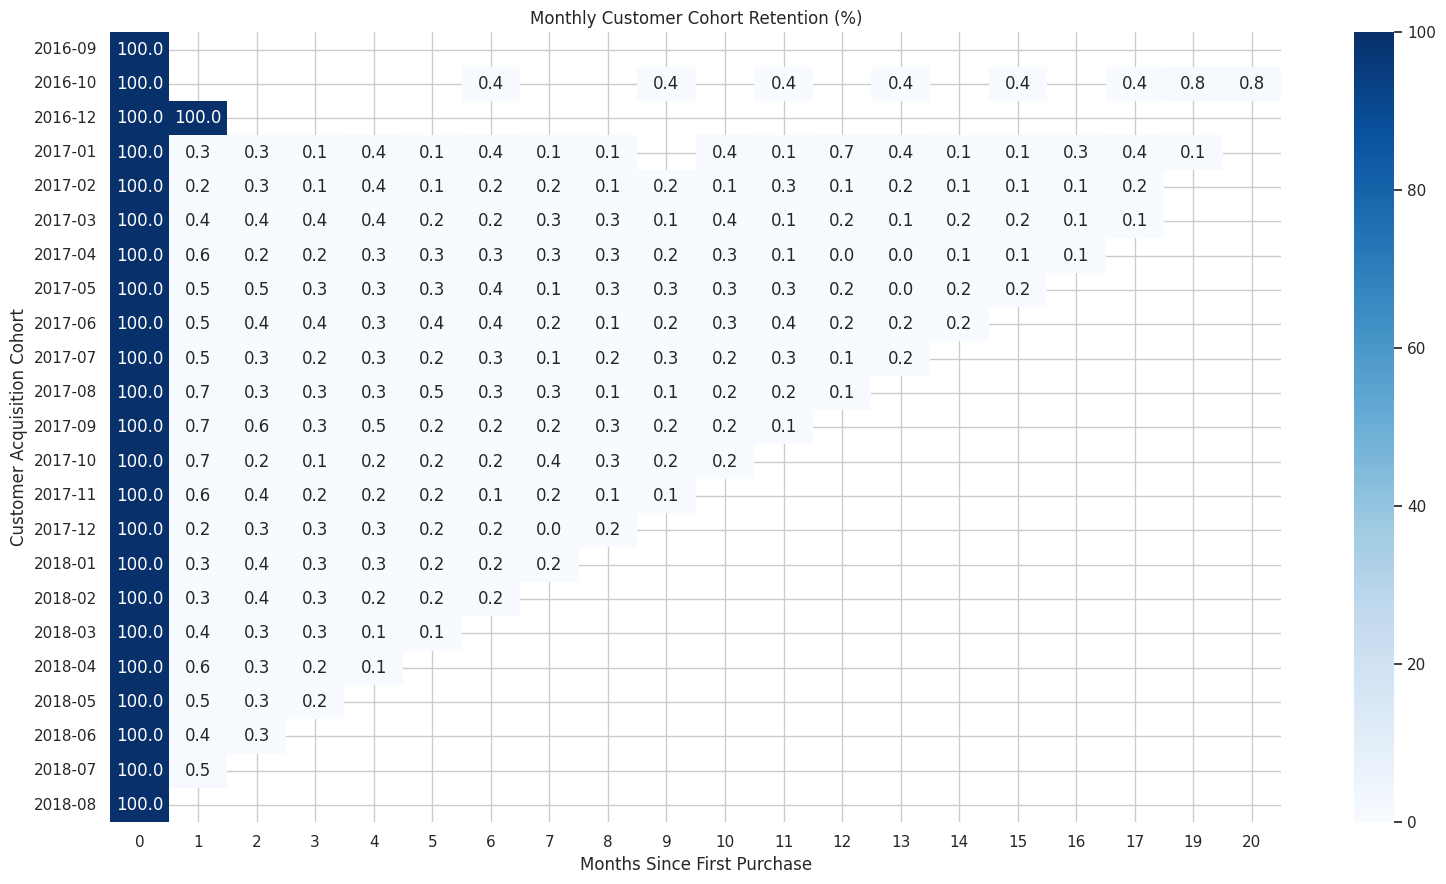

In [29]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    cohort_retention,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Monthly Customer Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Cohort")

plt.tight_layout()

plt.savefig(
    output_path / "cohort_retention_heatmap.png",
    dpi=300
)

plt.show()

In [30]:
import sqlite3
from pathlib import Path

db_path = Path("../olist_analytics.db")

conn = sqlite3.connect(
    db_path,
    timeout=60
)

print("SQLite database created:", db_path.resolve())

SQLite database created: /home/aditi/Downloads/job projects/ecommerce-growth-analytics/olist_analytics.db


In [31]:
sql_datasets = {
    "customers": customers,
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation
}

for table_name, dataframe in sql_datasets.items():

    dataframe.to_sql(
        table_name,
        conn,
        if_exists="replace",
        index=False,
        chunksize=10000
    )

    print(table_name, "created successfully")

conn.commit()

print("All 8 SQL tables created.")

customers created successfully
orders created successfully
order_items created successfully
payments created successfully
reviews created successfully
products created successfully
sellers created successfully
category_translation created successfully
All 8 SQL tables created.


In [32]:
index_queries = [
    "CREATE INDEX IF NOT EXISTS idx_orders_customer ON orders(customer_id)",
    "CREATE INDEX IF NOT EXISTS idx_orders_status ON orders(order_status)",
    "CREATE INDEX IF NOT EXISTS idx_orders_purchase ON orders(order_purchase_timestamp)",
    "CREATE INDEX IF NOT EXISTS idx_items_order ON order_items(order_id)",
    "CREATE INDEX IF NOT EXISTS idx_items_product ON order_items(product_id)",
    "CREATE INDEX IF NOT EXISTS idx_items_seller ON order_items(seller_id)",
    "CREATE INDEX IF NOT EXISTS idx_customers_unique ON customers(customer_unique_id)",
    "CREATE INDEX IF NOT EXISTS idx_reviews_order ON reviews(order_id)"
]

for query in index_queries:
    conn.execute(query)

conn.commit()

print("All indexes created successfully.")

All indexes created successfully.


In [33]:
table_info = pd.read_sql_query(
    """
    SELECT
        name AS table_name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name
    """,
    conn
)

table_info

,table_name
0,category_translation
1,customers
2,order_items
3,orders
4,payments
5,products
6,reviews
7,sellers


In [34]:
for table_name in sql_datasets:

    result = pd.read_sql_query(
        f"SELECT COUNT(*) AS total_rows FROM {table_name}",
        conn
    )

    print(
        table_name,
        ":",
        result.loc[0, "total_rows"],
        "rows"
    )

customers : 99441 rows
orders : 99441 rows
order_items : 112650 rows
payments : 103886 rows
reviews : 99224 rows
products : 32951 rows
sellers : 3095 rows
category_translation : 71 rows


In [35]:
query = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS month,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(oi.price), 2) AS product_sales,
    ROUND(SUM(oi.freight_value), 2) AS freight_charges,
    ROUND(SUM(oi.price + oi.freight_value), 2) AS total_gmv

FROM orders o

JOIN order_items oi
    ON o.order_id = oi.order_id

WHERE o.order_status = 'delivered'

GROUP BY month
ORDER BY month;
"""

sql_monthly_revenue = pd.read_sql_query(query, conn)

sql_monthly_revenue.head(20)

,month,total_orders,product_sales,freight_charges,total_gmv
0,2016-09,1,134.97,8.49,143.46
1,2016-10,265,"40,325.11","6,165.55","46,490.66"
2,2016-12,1,10.90,8.72,19.62
3,2017-01,750,"111,798.36","15,684.01","127,482.37"
4,2017-02,1653,"234,223.40","37,015.92","271,239.32"
5,2017-03,2546,"359,198.85","55,132.10","414,330.95"
6,2017-04,2303,"340,669.68","50,142.72","390,812.40"
7,2017-05,3546,"489,338.25","77,513.15","566,851.40"
8,2017-06,3135,"421,923.37","68,127.00","490,050.37"
9,2017-07,3872,"481,604.52","84,694.56","566,299.08"


In [36]:
query = """
WITH customer_frequency AS (

    SELECT
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS total_orders

    FROM customers c

    JOIN orders o
        ON c.customer_id = o.customer_id

    WHERE o.order_status = 'delivered'

    GROUP BY c.customer_unique_id
)

SELECT
    CASE
        WHEN total_orders > 1 THEN 'Repeat Customer'
        ELSE 'One-time Customer'
    END AS customer_type,

    COUNT(*) AS total_customers

FROM customer_frequency

GROUP BY customer_type;
"""

sql_customer_analysis = pd.read_sql_query(query, conn)

sql_customer_analysis

,customer_type,total_customers
0,One-time Customer,90557
1,Repeat Customer,2801


In [37]:
query = """
SELECT
    COALESCE(
        ct.product_category_name_english,
        p.product_category_name,
        'Unknown'
    ) AS category,

    COUNT(DISTINCT oi.order_id) AS total_orders,

    ROUND(SUM(oi.price), 2) AS product_sales,

    ROUND(AVG(oi.price), 2) AS average_item_price

FROM order_items oi

JOIN orders o
    ON oi.order_id = o.order_id

JOIN products p
    ON oi.product_id = p.product_id

LEFT JOIN category_translation ct
    ON p.product_category_name = ct.product_category_name

WHERE o.order_status = 'delivered'

GROUP BY category

ORDER BY product_sales DESC

LIMIT 15;
"""

sql_category_analysis = pd.read_sql_query(query, conn)

sql_category_analysis

,category,total_orders,product_sales,average_item_price
0,health_beauty,8647,"1,233,131.72",130.28
1,watches_gifts,5495,"1,166,176.98",199.04
2,bed_bath_table,9272,"1,023,434.76",93.44
3,sports_leisure,7530,"954,852.55",113.25
4,computers_accessories,6530,"888,724.61",116.26
5,furniture_decor,6307,"711,927.69",87.25
6,housewares,5743,"615,628.69",90.60
7,cool_stuff,3559,"610,204.10",164.12
8,auto,3810,"578,966.65",139.85
9,toys,3804,"471,286.48",116.94


In [38]:
query = """
SELECT
    s.seller_id,
    s.seller_city,
    s.seller_state,

    COUNT(DISTINCT oi.order_id) AS total_orders,

    ROUND(SUM(oi.price), 2) AS product_sales

FROM sellers s

JOIN order_items oi
    ON s.seller_id = oi.seller_id

JOIN orders o
    ON oi.order_id = o.order_id

WHERE o.order_status = 'delivered'

GROUP BY
    s.seller_id,
    s.seller_city,
    s.seller_state

ORDER BY product_sales DESC

LIMIT 20;
"""

sql_seller_analysis = pd.read_sql_query(query, conn)

sql_seller_analysis

,seller_id,seller_city,seller_state,total_orders,product_sales
0,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1124,"226,987.93"
1,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,348,"217,940.44"
2,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1772,"196,882.12"
3,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,578,"190,917.14"
4,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,973,"186,570.05"
5,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,319,"165,981.49"
6,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1311,"159,816.87"
7,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1145,"139,658.69"
8,1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,910,"138,208.56"
9,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1261,"131,836.71"


In [39]:
query = """
SELECT
    CASE
        WHEN julianday(order_delivered_customer_date) >
             julianday(order_estimated_delivery_date)
        THEN 'Late'
        ELSE 'On Time'
    END AS delivery_status,

    COUNT(*) AS total_orders

FROM orders

WHERE order_status = 'delivered'
AND order_delivered_customer_date IS NOT NULL
AND order_estimated_delivery_date IS NOT NULL

GROUP BY delivery_status;
"""

sql_delivery_analysis = pd.read_sql_query(query, conn)

sql_delivery_analysis

,delivery_status,total_orders
0,Late,7826
1,On Time,88644


In [40]:
conn.commit()
conn.close()

print("SQLite database saved successfully.")

SQLite database saved successfully.


In [41]:
exports = {
    "kpi_summary.csv": kpi_summary,
    "customer_summary.csv": customer_summary,
    "segment_analysis.csv": segment_analysis,
    "monthly_revenue.csv": monthly_revenue,
    "retention_analysis.csv": retention_analysis,
    "cohort_retention.csv": cohort_retention,
    "category_summary.csv": category_summary,
    "delivery_summary.csv": delivery_summary,
    "seller_analysis.csv": seller_analysis,
    "state_summary.csv": state_summary,
    "sql_monthly_revenue.csv": sql_monthly_revenue,
    "sql_customer_analysis.csv": sql_customer_analysis,
    "sql_category_analysis.csv": sql_category_analysis,
    "sql_seller_analysis.csv": sql_seller_analysis,
    "sql_delivery_analysis.csv": sql_delivery_analysis
}

for filename, dataframe in exports.items():
    dataframe.to_csv(output_path / filename, index=False)
    print(filename, "saved")

print("\nAll analysis results exported successfully.")

NameError: name 'monthly_revenue' is not defined

In [42]:
monthly_revenue = analysis_data.groupby("month").agg(
    total_orders=("order_id", "nunique"),
    product_revenue=("product_revenue", "sum"),
    freight_revenue=("freight_revenue", "sum"),
    total_revenue=("total_revenue", "sum")
).reset_index()

monthly_revenue["mom_growth_pct"] = (
    monthly_revenue["total_revenue"].pct_change() * 100
)

monthly_revenue.head(10)

,month,total_orders,product_revenue,freight_revenue,total_revenue,mom_growth_pct
0,2016-09,1,134.97,8.49,143.46,NaN
1,2016-10,265,"40,325.11","6,165.55","46,490.66","32,306.71"
2,2016-12,1,10.90,8.72,19.62,-99.96
3,2017-01,750,"111,798.36","15,684.01","127,482.37","649,657.24"
4,2017-02,1653,"234,223.40","37,015.92","271,239.32",112.77
5,2017-03,2546,"359,198.85","55,132.10","414,330.95",52.75
6,2017-04,2303,"340,669.68","50,142.72","390,812.40",-5.68
7,2017-05,3546,"489,338.25","77,513.15","566,851.40",45.04
8,2017-06,3135,"421,923.37","68,127.00","490,050.37",-13.55
9,2017-07,3872,"481,604.52","84,694.56","566,299.08",15.56


In [44]:
exports = {
    "customer_summary.csv": customer_summary,
    "segment_analysis.csv": segment_analysis,
    "monthly_revenue.csv": monthly_revenue,
    "retention_analysis.csv": retention_analysis,
    "cohort_retention.csv": cohort_retention,
    "sql_monthly_revenue.csv": sql_monthly_revenue,
    "sql_customer_analysis.csv": sql_customer_analysis,
    "sql_category_analysis.csv": sql_category_analysis,
    "sql_seller_analysis.csv": sql_seller_analysis,
    "sql_delivery_analysis.csv": sql_delivery_analysis
}

for filename, dataframe in exports.items():
    dataframe.to_csv(output_path / filename, index=False)
    print(filename, "saved successfully")

print("\nAll analysis results exported successfully.")

customer_summary.csv saved successfully
segment_analysis.csv saved successfully
monthly_revenue.csv saved successfully
retention_analysis.csv saved successfully
cohort_retention.csv saved successfully
sql_monthly_revenue.csv saved successfully
sql_customer_analysis.csv saved successfully
sql_category_analysis.csv saved successfully
sql_seller_analysis.csv saved successfully
sql_delivery_analysis.csv saved successfully

All analysis results exported successfully.


In [45]:
saved_files = sorted(output_path.glob("*.csv"))

print("Total CSV reports:", len(saved_files))

for file in saved_files:
    print(file.name)

Total CSV reports: 10
cohort_retention.csv
customer_summary.csv
monthly_revenue.csv
retention_analysis.csv
segment_analysis.csv
sql_category_analysis.csv
sql_customer_analysis.csv
sql_delivery_analysis.csv
sql_monthly_revenue.csv
sql_seller_analysis.csv


In [46]:
from pathlib import Path

sql_path = Path("../SQL")
sql_path.mkdir(exist_ok=True)

sql_scripts = {
    "01_monthly_revenue.sql": """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS month,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(oi.price), 2) AS product_sales,
    ROUND(SUM(oi.freight_value), 2) AS freight_charges,
    ROUND(SUM(oi.price + oi.freight_value), 2) AS total_gmv
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY month
ORDER BY month;
""",

    "02_customer_repeat_analysis.sql": """
WITH customer_frequency AS (
    SELECT
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS total_orders
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
)
SELECT
    CASE
        WHEN total_orders > 1 THEN 'Repeat Customer'
        ELSE 'One-time Customer'
    END AS customer_type,
    COUNT(*) AS total_customers
FROM customer_frequency
GROUP BY customer_type;
""",

    "03_category_performance.sql": """
SELECT
    COALESCE(
        ct.product_category_name_english,
        p.product_category_name,
        'Unknown'
    ) AS category,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    ROUND(SUM(oi.price), 2) AS product_sales,
    ROUND(AVG(oi.price), 2) AS average_item_price
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
JOIN products p ON oi.product_id = p.product_id
LEFT JOIN category_translation ct
    ON p.product_category_name = ct.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY product_sales DESC
LIMIT 15;
""",

    "04_seller_performance.sql": """
SELECT
    s.seller_id,
    s.seller_city,
    s.seller_state,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    ROUND(SUM(oi.price), 2) AS product_sales
FROM sellers s
JOIN order_items oi ON s.seller_id = oi.seller_id
JOIN orders o ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY s.seller_id, s.seller_city, s.seller_state
ORDER BY product_sales DESC
LIMIT 20;
""",

    "05_delivery_performance.sql": """
SELECT
    CASE
        WHEN julianday(order_delivered_customer_date) >
             julianday(order_estimated_delivery_date)
        THEN 'Late'
        ELSE 'On Time'
    END AS delivery_status,
    COUNT(*) AS total_orders
FROM orders
WHERE order_status = 'delivered'
AND order_delivered_customer_date IS NOT NULL
AND order_estimated_delivery_date IS NOT NULL
GROUP BY delivery_status;
"""
}

for filename, sql_code in sql_scripts.items():
    (sql_path / filename).write_text(sql_code.strip() + "\n")

print("SQL scripts saved:")
for file in sorted(sql_path.glob("*.sql")):
    print(file.name)

SQL scripts saved:
01_monthly_revenue.sql
02_customer_repeat_analysis.sql
03_category_performance.sql
04_seller_performance.sql
05_delivery_performance.sql


In [47]:
from pathlib import Path

dashboard_path = Path("../dashboard")
dashboard_path.mkdir(exist_ok=True)

app_code = r'''
import streamlit as st
import pandas as pd
import sqlite3
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
DB_PATH = ROOT / "olist_analytics.db"

st.set_page_config(
    page_title="E-Commerce Business Intelligence",
    page_icon="📊",
    layout="wide"
)

st.title("E-Commerce Business Intelligence Dashboard")
st.caption("Business analytics using the Olist Brazilian E-Commerce dataset")

@st.cache_data
def load_data():
    conn = sqlite3.connect(DB_PATH)

    monthly = pd.read_sql_query("""
        SELECT
            strftime('%Y-%m', o.order_purchase_timestamp) AS month,
            COUNT(DISTINCT o.order_id) AS total_orders,
            ROUND(SUM(oi.price), 2) AS product_sales,
            ROUND(SUM(oi.price + oi.freight_value), 2) AS total_gmv
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        WHERE o.order_status = 'delivered'
        GROUP BY month
        ORDER BY month
    """, conn)

    categories = pd.read_sql_query("""
        SELECT
            COALESCE(ct.product_category_name_english,
                     p.product_category_name, 'Unknown') AS category,
            ROUND(SUM(oi.price), 2) AS product_sales
        FROM order_items oi
        JOIN orders o ON oi.order_id = o.order_id
        JOIN products p ON oi.product_id = p.product_id
        LEFT JOIN category_translation ct
            ON p.product_category_name = ct.product_category_name
        WHERE o.order_status = 'delivered'
        GROUP BY category
        ORDER BY product_sales DESC
        LIMIT 10
    """, conn)

    customers = pd.read_sql_query("""
        SELECT
            customer_type,
            COUNT(*) AS total_customers
        FROM (
            SELECT
                c.customer_unique_id,
                CASE
                    WHEN COUNT(DISTINCT o.order_id) > 1
                    THEN 'Repeat Customer'
                    ELSE 'One-time Customer'
                END AS customer_type
            FROM customers c
            JOIN orders o ON c.customer_id = o.customer_id
            WHERE o.order_status = 'delivered'
            GROUP BY c.customer_unique_id
        )
        GROUP BY customer_type
    """, conn)

    delivery = pd.read_sql_query("""
        SELECT
            CASE
                WHEN julianday(order_delivered_customer_date) >
                     julianday(order_estimated_delivery_date)
                THEN 'Late'
                ELSE 'On Time'
            END AS delivery_status,
            COUNT(*) AS total_orders
        FROM orders
        WHERE order_status = 'delivered'
        AND order_delivered_customer_date IS NOT NULL
        AND order_estimated_delivery_date IS NOT NULL
        GROUP BY delivery_status
    """, conn)

    conn.close()
    return monthly, categories, customers, delivery

try:
    monthly, categories, customers, delivery = load_data()

    total_gmv = monthly["total_gmv"].sum()
    total_orders = monthly["total_orders"].sum()

    repeat_count = customers.loc[
        customers["customer_type"] == "Repeat Customer",
        "total_customers"
    ].sum()

    total_customers = customers["total_customers"].sum()
    repeat_rate = repeat_count / total_customers * 100

    late_orders = delivery.loc[
        delivery["delivery_status"] == "Late",
        "total_orders"
    ].sum()

    delivered_orders = delivery["total_orders"].sum()
    late_rate = late_orders / delivered_orders * 100

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Total GMV", f"R$ {total_gmv:,.0f}")
    col2.metric("Delivered Orders", f"{total_orders:,}")
    col3.metric("Repeat Purchase Rate", f"{repeat_rate:.2f}%")
    col4.metric("Late Delivery Rate", f"{late_rate:.2f}%")

    st.divider()

    left, right = st.columns(2)

    with left:
        st.subheader("Monthly GMV")
        st.line_chart(
            monthly.set_index("month")["total_gmv"]
        )

    with right:
        st.subheader("Monthly Order Volume")
        st.bar_chart(
            monthly.set_index("month")["total_orders"]
        )

    st.divider()

    left, right = st.columns(2)

    with left:
        st.subheader("Top Product Categories")
        st.bar_chart(
            categories.set_index("category")["product_sales"]
        )

    with right:
        st.subheader("Customer Segmentation")
        st.bar_chart(
            customers.set_index("customer_type")["total_customers"]
        )

    st.divider()

    st.subheader("Delivery Performance")
    st.dataframe(delivery, use_container_width=True)

    st.subheader("Monthly Business Data")
    st.dataframe(monthly, use_container_width=True)

    st.caption(
        "Source: Olist Brazilian E-Commerce public dataset (2016–2018). "
        "GMV includes product prices and freight charges for delivered orders; "
        "it is not company profit or net revenue."
    )

except Exception as error:
    st.error(f"Dashboard could not load: {error}")
    st.info("Check that olist_analytics.db exists in the project root.")
'''

(dashboard_path / "app.py").write_text(app_code)

print("Dashboard application created:")
print((dashboard_path / "app.py").resolve())

Dashboard application created:
/home/aditi/Downloads/job projects/ecommerce-growth-analytics/dashboard/app.py


In [48]:
requirements = """
pandas
numpy
matplotlib
seaborn
streamlit
"""

Path("../requirements.txt").write_text(requirements.strip() + "\n")

print("requirements.txt created successfully.")

requirements.txt created successfully.
